# Observed state transition graphs with the Sizek cell cycle model

This notebook reproduces section 3.9 of the CoLoMoTo tutorial on the Sizek *et al.* (2019) model of cell cycle and apoptosis ([colomoto-tutorial-sizek](https://github.com/colomoto/colomoto-tutorial-sizek)), and uses it to test the *observed graph* functionality of pyMaBoSS.

An observed graph is a compressed state transition graph. A few nodes are flagged as *observed* (`in_graph`), and MaBoSS counts, over all simulated trajectories, the transitions between the activity patterns of these nodes. Once normalised, each row gives the probability of the next observed pattern, given the current one.

Observed nodes can be set from Python with `network.set_observed_graph_nodes(...)`, or directly in the cfg file:

```
CyclinA.in_graph = True;
```

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import maboss

BND = "models/Sizek2019.bnd"
CFG = "models/Sizek2019.cfg"

# Simulation settings used in the CoLoMoTo tutorial
PARAMS = dict(sample_count=10000, max_time=500, time_tick=5, thread_count=16)
CYCLINS = ["CyclinA", "CyclinB", "CyclinE"]

## 1. Loading a cfg declaring observed nodes

The cfg file already sets the initial state of Sizek *et al.* (their Figure 5), and flags the three main cyclins as observed:

In [2]:
with open(CFG) as f:
    print("".join(line for line in f if "in_graph" in line))

CyclinA.in_graph = True;
CyclinB.in_graph = True;
CyclinE.in_graph = True;



In [3]:
sim = maboss.load(BND, CFG)
sim.update_parameters(**PARAMS)

observed = [name for name, node in sim.network.items() if node.in_graph]
print("Observed nodes (MaBoSS):", observed)

Observed nodes (MaBoSS): ['CyclinE', 'CyclinA', 'CyclinB']


## 2. Order of cyclin activations in the wild type

We expect the cyclins to be activated in the order CyclinE, CyclinA, CyclinB, and inactivated in the same order. The mean trajectories show this sequence as damped oscillations:

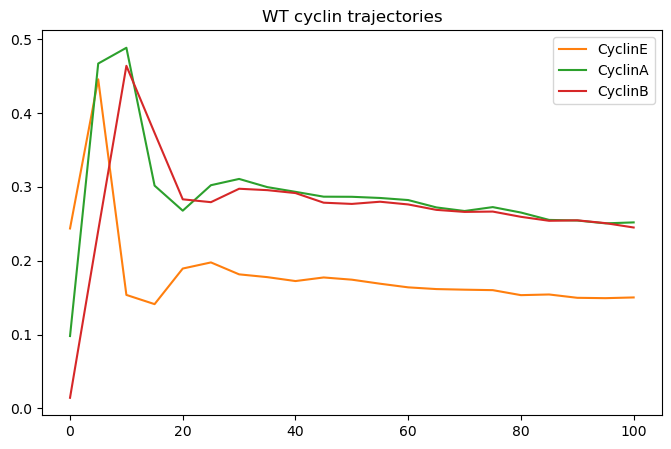

In [4]:
sim.network.set_output(CYCLINS)
res = sim.run()

fig, ax = plt.subplots(figsize=(8, 5))
res.plot_node_trajectory(axes=ax, until=100)
ax.set_title("WT cyclin trajectories");

The observed graph gives the same information for individual trajectories. Rows are the current pattern of cyclins, columns are the next one:

In [5]:
graph = res.get_observed_graph()
graph.round(3)

,<nil>,CyclinB,CyclinE,CyclinB -- CyclinE,CyclinA,CyclinB -- CyclinA,CyclinE -- CyclinA,CyclinB -- CyclinE -- CyclinA
State,,,,,,,,
<nil>,0.000,0.022,0.797,0.000,0.181,0.000,0.000,0.000
CyclinB,0.980,0.000,0.000,0.006,0.000,0.014,0.000,0.000
CyclinE,0.130,0.000,0.000,0.002,0.000,0.000,0.868,0.000
CyclinB -- CyclinE,0.000,0.551,0.314,0.000,0.000,0.000,0.000,0.135
CyclinA,0.475,0.000,0.000,0.000,0.000,0.509,0.016,0.000
CyclinB -- CyclinA,0.000,0.838,0.000,0.000,0.160,0.000,0.000,0.002
CyclinE -- CyclinA,0.000,0.000,0.002,0.000,0.641,0.000,0.000,0.356
CyclinB -- CyclinE -- CyclinA,0.000,0.000,0.000,0.021,0.000,0.976,0.003,0.000


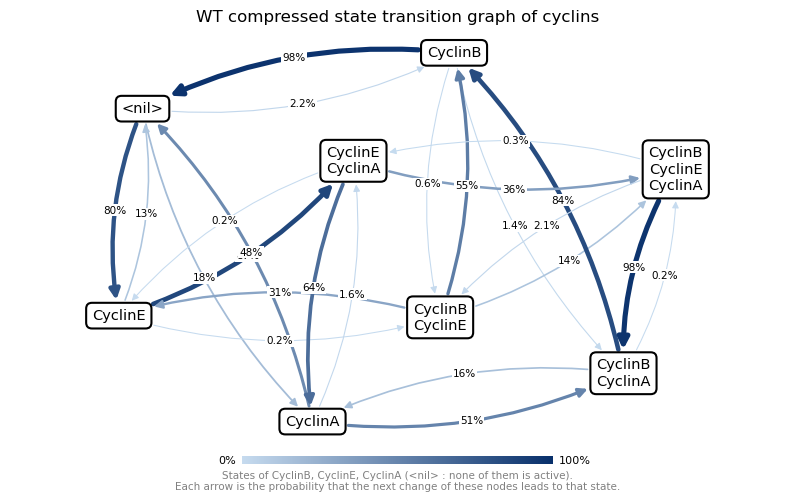

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
res.plot_observed_graph(axes=ax)
ax.set_title("WT compressed state transition graph of cyclins");

**Test:** following the most likely transition from each state recovers the expected cycle, from `<nil>` (G0) back to `<nil>`.

In [7]:
expected_cycle = {
    "<nil>": "CyclinE",
    "CyclinE": "CyclinE -- CyclinA",
    "CyclinE -- CyclinA": "CyclinA",
    "CyclinA": "CyclinB -- CyclinA",
    "CyclinB -- CyclinA": "CyclinB",
    "CyclinB": "<nil>",
}
most_likely = graph.idxmax(axis=1)
pd.DataFrame({"most likely next": most_likely[list(expected_cycle)],
              "probability": graph.max(axis=1)[list(expected_cycle)].round(3)})

,most likely next,probability
State,,
<nil>,CyclinE,0.797
CyclinE,CyclinE -- CyclinA,0.868
CyclinE -- CyclinA,CyclinA,0.641
CyclinA,CyclinB -- CyclinA,0.509
CyclinB -- CyclinA,CyclinB,0.838
CyclinB,<nil>,0.980


## 3. When does apoptosis start along the cell cycle?

We now simulate the model to see where in the cycle Casp3 gets activated:

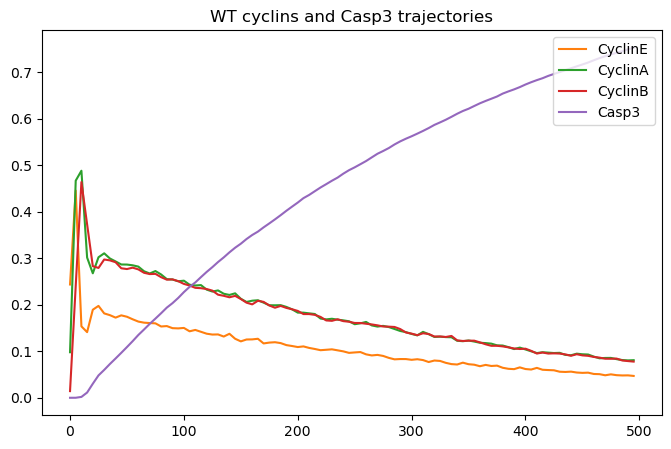

In [8]:
outputs = ["Casp3"] + CYCLINS
sim.network.set_output(outputs)
sim.network.set_observed_graph_nodes(outputs)

res_casp3 = sim.run()

fig, ax = plt.subplots(figsize=(8, 5))
res_casp3.plot_node_trajectory(axes=ax)
ax.set_title("WT cyclins and Casp3 trajectories");

Cells first follow the cycle, then activate Casp3. To keep the graph readable, transitions with probability below 2% are not drawn:

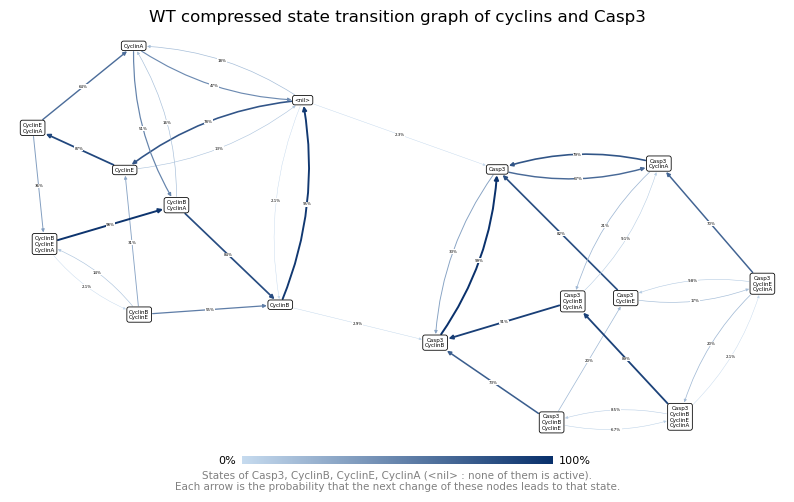

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
res_casp3.plot_observed_graph(axes=ax, prob_cutoff=0.02)
ax.set_title("WT compressed state transition graph of cyclins and Casp3");

For each pattern of cyclins without Casp3, the probability that the next transition activates Casp3 is the sum of the columns containing Casp3:

In [10]:
def casp3_entry(graph):
    casp3_on = [s for s in graph.columns if "Casp3" in s]
    casp3_off = [s for s in graph.index if "Casp3" not in s]
    return graph.loc[casp3_off, casp3_on].sum(axis=1)

entry_wt = casp3_entry(res_casp3.get_observed_graph())
entry_wt.round(3).to_frame("P(Casp3 activation)")

,P(Casp3 activation)
State,
<nil>,0.023
CyclinB,0.029
CyclinE,0.003
CyclinB -- CyclinE,0.003
CyclinA,0.003
CyclinB -- CyclinA,0.002
CyclinE -- CyclinA,0.000
CyclinB -- CyclinE -- CyclinA,0.000


## 4. Ectopic p110_H activity blocks apoptosis

In the original model, p110_H activates PI3K and AKT, which inhibit cell death. We force p110_H ON:

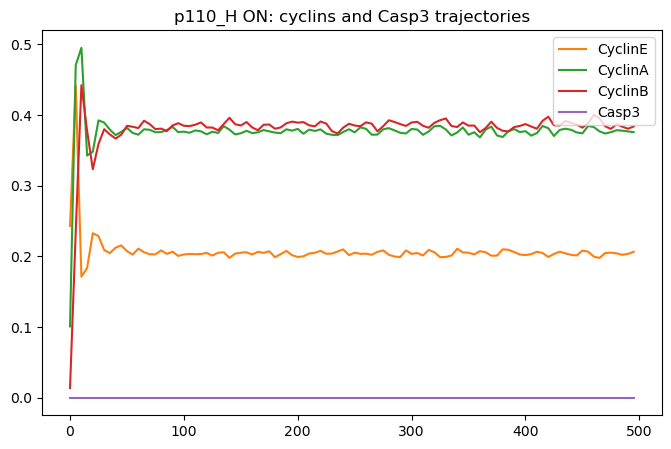

In [11]:
mut_p110 = sim.copy()
mut_p110.mutate("p110_H", "ON")
res_p110 = mut_p110.run()

fig, ax = plt.subplots(figsize=(8, 5))
res_p110.plot_node_trajectory(axes=ax)
ax.set_title("p110_H ON: cyclins and Casp3 trajectories");

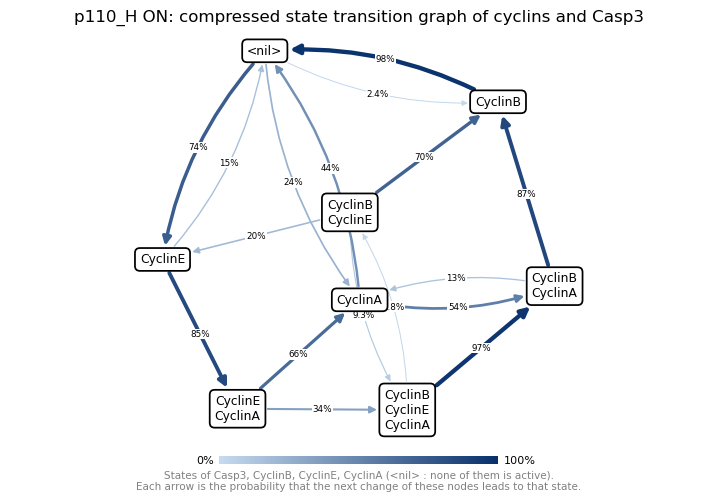

In [12]:
fig, ax = plt.subplots(figsize=(9, 6))
res_p110.plot_observed_graph(axes=ax, prob_cutoff=0.02)
ax.set_title("p110_H ON: compressed state transition graph of cyclins and Casp3");

**Test:** with p110_H ON, no trajectory activates Casp3, and the cycle is kept.

In [13]:
entry_p110 = casp3_entry(res_p110.get_observed_graph())
print("Max P(Casp3 activation) with p110_H ON:", entry_p110.max())

graph_p110 = res_p110.get_observed_graph()

Max P(Casp3 activation) with p110_H ON: 0.0


## Summary

- The observed graphs reproduce section 3.9 of the CoLoMoTo tutorial: the cyclin cycle (E, then A, then B), the two entry points into apoptosis (G0 and G2/M), and the loss of apoptosis when p110_H is forced ON.